# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [31]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [32]:
# Step 1: Initial Data Understanding
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
print()
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
profiles = df.drop(columns=['customer_id', 'product'])
print("Unique customer profiles (ignoring customer_id):", len(profiles.drop_duplicates()))
print("\nUnique values in 'female':", df['female'].unique())
df.describe().T

Shape: (29504, 15)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

Missing values:
 customer_id       0
answe

,count,mean,std,min,25%,50%,75%,max
customer_id,29504.0,14850.475563,8517.254310,99.0,7474.75,14850.5,22226.25,29602.0
answered,29504.0,0.546638,0.497829,0.0,0.00,1.0,1.00,1.0
income,29504.0,33766.893303,29379.202710,-65600.0,13550.00,23310.0,41690.00,159450.0
age,29504.0,34.773454,11.369865,19.0,26.00,32.0,40.00,132.0
job,29504.0,1.915401,0.658183,0.0,2.00,2.0,2.00,3.0
num_dependents,29504.0,1.140998,0.348025,1.0,1.00,1.0,1.00,2.0
rent,29504.0,0.210412,0.407608,0.0,0.00,0.0,0.00,1.0
own_res,29504.0,0.681128,0.466047,0.0,0.00,1.0,1.00,1.0
new_car,29502.0,0.240797,0.427575,0.0,0.00,0.0,0.00,1.0
chk_acct,29504.0,1.468547,1.234727,0.0,0.00,1.0,3.00,3.0


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The data has 29,504 rows and 15 columns, and several things look off. female is stored as text because one row has the value "M" instead of 0/1. new_car has 2 missing values, and there are 3 fully duplicated rows. The summary statistics show impossible values: a minimum income of -$65,600, a maximum age of 132, and one customer with 3,345 accounts (the next highest is 8). Also, ignoring customer_id, there are only 469 unique customer profiles. Each one repeats about 64 times under different IDs. Finally, product is recorded after the call, and a value of 0 always means the customer didn't answer, so it can't be used to predict answering.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [33]:
# 2.1 Data Cleanup
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove the 2 rows missing new_car (too few to be worth imputing)
df_clean = df_clean.dropna(subset=['new_car'])

# Remove outliers / impossible values
df_clean = df_clean[df_clean['income'] >= 0]        # negative income
df_clean = df_clean[df_clean['age'] <= 100]         # age of 132
df_clean = df_clean[df_clean['num_accts'] <= 20]    # 3,345 accounts

# Drop columns that can't help predict answering:
#   customer_id = just an ID
#   product     = only known AFTER the call (it leaks the answer)
df_clean = df_clean.drop(columns=['customer_id', 'product'])

print("Rows before:", len(df), " Rows after:", len(df_clean))

Rows before: 29504  Rows after: 29495


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed the 3 duplicate rows. I deleted the 2 rows missing new_car instead of imputing them, because 2 out of 29,504 is too few to affect the model and guessing a 0/1 value would just add noise. For outliers, I removed rows with negative income, the age of 132 and the 3,345 accounts, since these are impossible or obvious data-entry errors rather than real extreme customers. I also removed the one row where female was "M". In total 10 rows were removed, leaving 29,494.

2.6 I removed customer_id because it's just a label with no relationship to whether someone answers. I removed product because it's only known after the call happens. It also directly reveals the answer (product = 0 means no answer), so leaving it in would cause data leakage and give fake 100% accuracy.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [34]:
# 2.2 Standardize variables
# Remove the row where 'female' was entered as 'M' (not a valid 0/1 value)
df_clean = df_clean[pd.to_numeric(df_clean['female'], errors='coerce').notnull()].copy()

df_clean['answered'] = df_clean['answered'].astype(bool)

int_cols = ['female', 'new_car']
for col in int_cols:
    df_clean[col] = df_clean[col].astype(int)

df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,int64


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [35]:
# 2.3 Convert variables to categorical
cat_cols = ['job', 'chk_acct', 'sav_acct']
for col in cat_cols:
    df_clean[col] = df_clean[col].astype('category')

df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,category
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,category


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



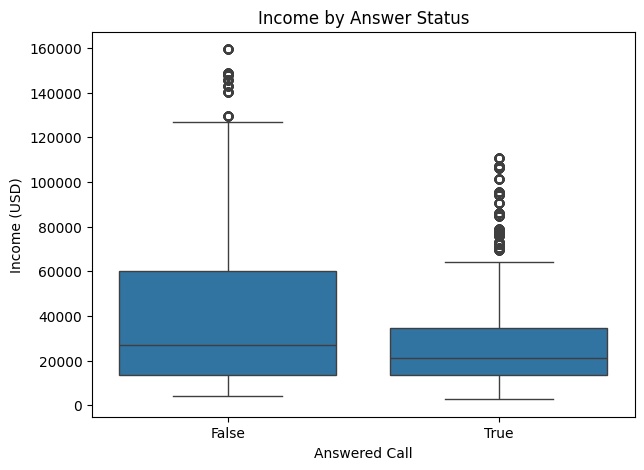

In [36]:
# Chart 1: Income by answer status (box plot)
plt.figure(figsize=(7, 5))
sns.boxplot(x='answered', y='income', data=df_clean)
plt.title('Income by Answer Status')
plt.xlabel('Answered Call')
plt.ylabel('Income (USD)')
plt.show()

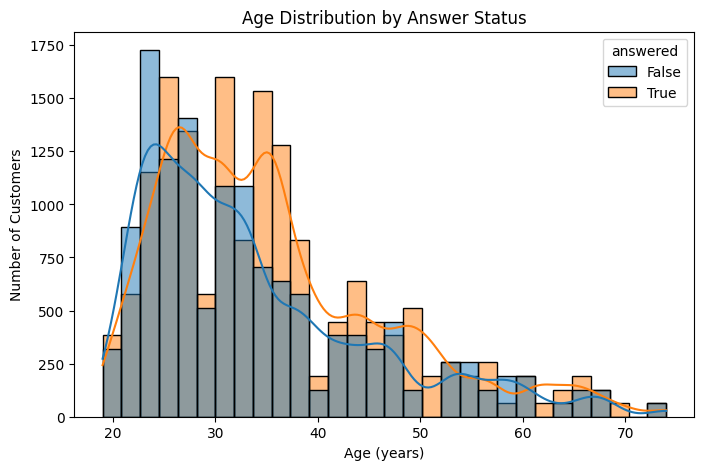

In [37]:
# Chart 2: Age distribution by answer status (histogram)
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x='age', hue='answered', bins=30, multiple='layer', kde=True)
plt.title('Age Distribution by Answer Status')
plt.xlabel('Age (years)')
plt.ylabel('Number of Customers')
plt.show()

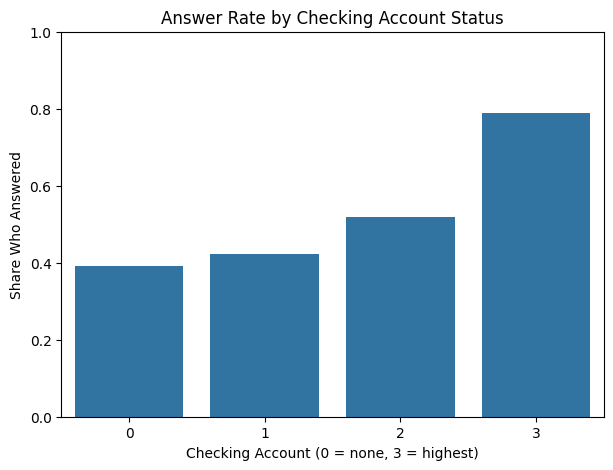

In [38]:
# Chart 3: Answer rate by checking account status (bar chart)
plt.figure(figsize=(7, 5))
sns.barplot(x='chk_acct', y='answered', data=df_clean, errorbar=None)
plt.title('Answer Rate by Checking Account Status')
plt.xlabel('Checking Account (0 = none, 3 = highest)')
plt.ylabel('Share Who Answered')
plt.ylim(0, 1)
plt.show()

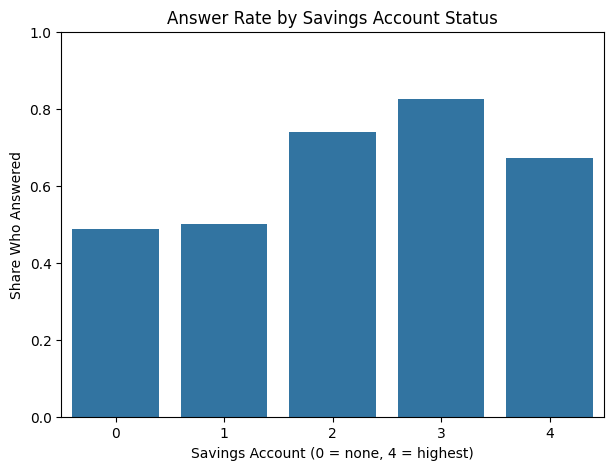

In [39]:
# Chart 4: Answer rate by savings account status (bar chart)
plt.figure(figsize=(7, 5))
sns.barplot(x='sav_acct', y='answered', data=df_clean, errorbar=None)
plt.title('Answer Rate by Savings Account Status')
plt.xlabel('Savings Account (0 = none, 4 = highest)')
plt.ylabel('Share Who Answered')
plt.ylim(0, 1)
plt.show()

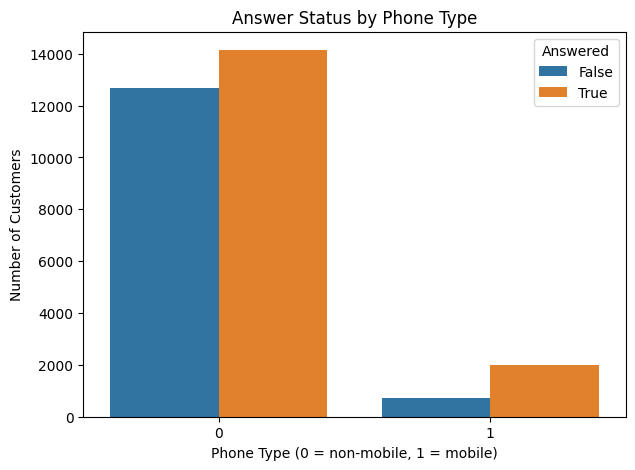

In [40]:
# Chart 5: Answered vs not answered by phone type (count plot)
plt.figure(figsize=(7, 5))
sns.countplot(x='mobile', hue='answered', data=df_clean)
plt.title('Answer Status by Phone Type')
plt.xlabel('Phone Type (0 = non-mobile, 1 = mobile)')
plt.ylabel('Number of Customers')
plt.legend(title='Answered')
plt.show()

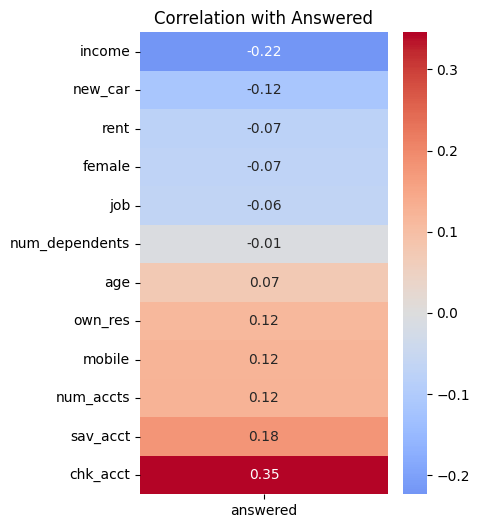

In [41]:
# Chart 6: Correlation of each variable with answering (heatmap)
corr = df_clean.astype(float).corr()[['answered']].drop('answered').sort_values('answered')
plt.figure(figsize=(4, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation with Answered')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking account status has the strongest relationship with answering (correlation 0.35). Customers with the highest checking balance answered 79% of the time, compared with 39% for customers with no checking account. Income is next (-0.22): customers who answered had a lower median income ($21,265 vs. $27,120), and almost all of the highest-income customers didn't answer. Savings account status (0.18), mobile phone (74% answer rate vs. 53%) and number of accounts (0.12) also show clear relationships.

3.7. Number of dependents is the weakest (correlation -0.01; 55% vs. 54% answer rate), and job, female and rent are also weak. I kept them because decision trees and ensemble models give little weight to features that don't help split the data, so leaving them in doesn't hurt. Removing them also wouldn't change the results much.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [42]:
# 4.1 Base probability of answering
base_prob = df_clean['answered'].mean()
print(f"Base probability of answering: {base_prob:.4f}")

Base probability of answering: 0.5467


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [43]:
# 4.2 Split training and testing data
X = pd.get_dummies(df_clean.drop(columns=['answered']), drop_first=True)
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), " Testing rows:", len(X_test))

Training rows: 23595  Testing rows: 5899


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

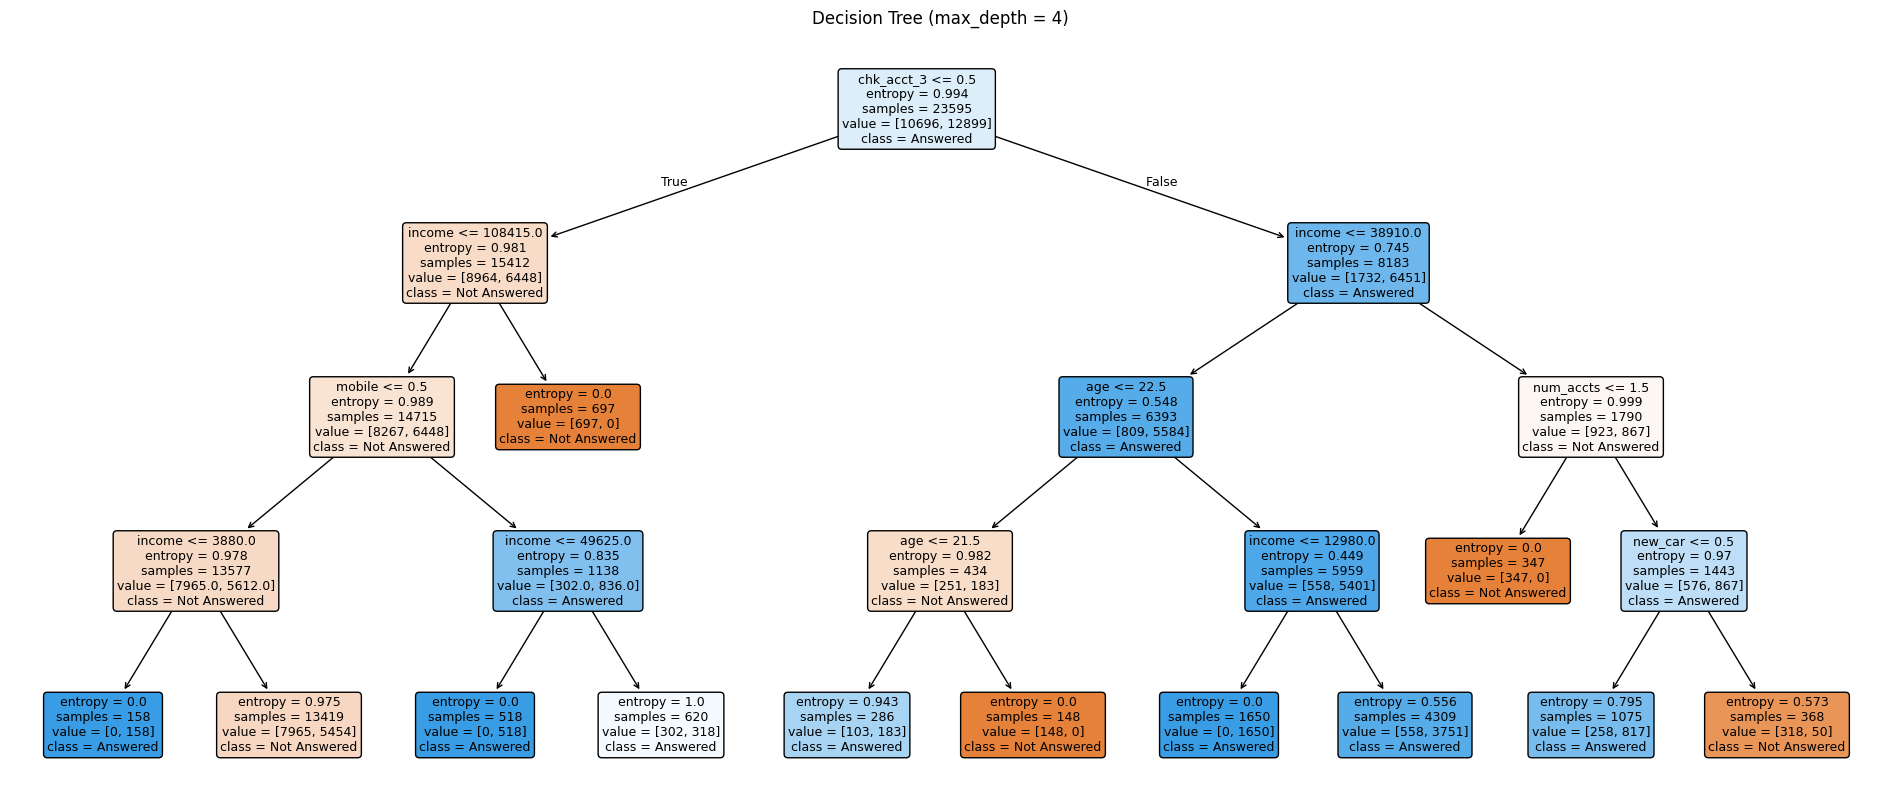

In [44]:
# 4.3 Create and visualize a decision tree
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

plt.figure(figsize=(24, 10))
plot_tree(dt_model, feature_names=X.columns.tolist(),
          class_names=['Not Answered', 'Answered'], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree (max_depth = 4)')
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [45]:
# 4.4 Accuracy of the tree
y_pred_dt = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Decision tree test accuracy: {dt_accuracy:.4f}")
print(f"Base probability:            {base_prob:.4f}")
print(f"Improvement:                 {dt_accuracy - base_prob:.4f}")

Decision tree test accuracy: 0.7188
Base probability:            0.5467
Improvement:                 0.1721


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The base probability of answering is 54.7%, which means that if we predicted "answers" for everyone we'd be right about 55% of the time. The depth-4 decision tree gets 71.9% test accuracy, an improvement of about 17 percentage points.

2. Yes, that's significant for the business. The model is right about 7 out of 10 times instead of about 5.5 out of 10, so AdviseInvest can do a much better job of knowing which scheduled calls will actually happen and staffing reps around them.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [46]:
# 4.5 Confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

[[2359  315]
 [1344 1881]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

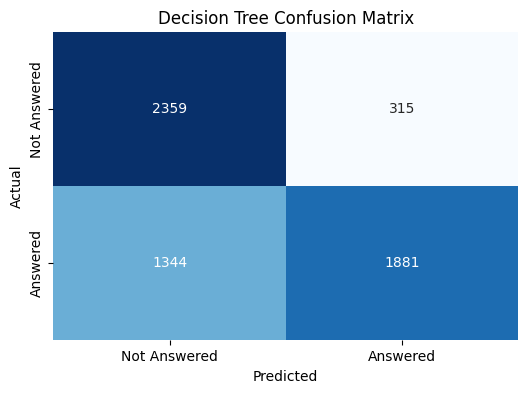

In [47]:
# 4.5 Visual confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Not Answered', 'Answered'], yticklabels=['Not Answered', 'Answered'])
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [48]:
# 4.6 Check for overfitting / underfitting
train_acc_dt = accuracy_score(y_train, dt_model.predict(X_train))
test_acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Training accuracy: {train_acc_dt:.4f}")
print(f"Testing accuracy:  {test_acc_dt:.4f}")
print(f"Difference:        {train_acc_dt - test_acc_dt:.4f}")

Training accuracy: 0.7150
Testing accuracy:  0.7188
Difference:        -0.0038


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. The model is reasonably balanced and not overfit. Training accuracy (71.5%) and test accuracy (71.9%) are nearly the same (difference of -0.4 points), and both are well above the 54.7% baseline. If anything, a depth-4 tree is a little too simple for this data. It isn't underfit in the sense of being near the baseline, but there's room for it to learn more.
2. If it were overfit, I could lower max_depth, raise min_samples_split or min_samples_leaf, or use fewer features.
3. Since it's slightly too simple, I can increase max_depth so the tree can find more patterns.


# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [49]:
# 5.1 Profit using the model
def calculate_profit(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[False, True]).ravel()
    profit = tp * 75 - fp * 25
    return profit, tp, fp

dt_profit, dt_tp, dt_fp = calculate_profit(y_test, y_pred_dt)
print(f"True positives: {dt_tp}  False positives: {dt_fp}")
print(f"Decision tree profit: ${dt_profit:,}")

True positives: 1881  False positives: 315
Decision tree profit: $133,200


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [50]:
# 5.2 Default profit (call everyone)
call_all = np.ones(len(y_test), dtype=bool)
default_profit, default_tp, default_fp = calculate_profit(y_test, call_all)
print(f"Answered (TP): {default_tp}  Did not answer (FP): {default_fp}")
print(f"Default profit (call everyone): ${default_profit:,}")
print(f"Model profit:                   ${dt_profit:,}")
print(f"Difference:                     ${dt_profit - default_profit:,}")

Answered (TP): 3225  Did not answer (FP): 2674
Default profit (call everyone): $175,025
Model profit:                   $133,200
Difference:                     $-41,825


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone makes \$175,025 on the test set (3,225 answers × \$75 minus 2,674 no-answers × \$25). Calling only the customers the depth-4 tree recommends makes \$133,200, which is **\$41,825 less**.
2. That's a significant amount, and it shows that a more accurate model isn't automatically more profitable. The tree avoids 2,359 wasted calls, but it also skips 1,344 customers who would have answered. Each missed customer costs \$75 in lost profit, while each wasted call only costs \$25, so being too cautious loses money. The model needs to catch more of the answerers before it beats calling everyone.

## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [52]:
# 5.3 Tune the tree: try several depths and keep the best test accuracy
results = []
for depth in range(2, 13):
    m = DecisionTreeClassifier(criterion='entropy', max_depth=depth, min_samples_leaf=20, random_state=42)
    m.fit(X_train, y_train)
    results.append({'max_depth': depth,
                    'train_acc': accuracy_score(y_train, m.predict(X_train)),
                    'test_acc': accuracy_score(y_test, m.predict(X_test))})
tuning = pd.DataFrame(results)
print(tuning.round(4))

best_depth = int(tuning.loc[tuning['test_acc'].idxmax(), 'max_depth'])
tuned_dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=best_depth,
                                        min_samples_leaf=20, random_state=42)
tuned_dt_model.fit(X_train, y_train)
y_pred_tuned_dt = tuned_dt_model.predict(X_test)
tuned_dt_accuracy = accuracy_score(y_test, y_pred_tuned_dt)
tuned_dt_profit, tuned_dt_tp, tuned_dt_fp = calculate_profit(y_test, y_pred_tuned_dt)

print(f"\nBest max_depth: {best_depth}")
print(f"Original tree accuracy: {dt_accuracy:.4f}   profit: ${dt_profit:,}")
print(f"Tuned tree accuracy:    {tuned_dt_accuracy:.4f}   profit: ${tuned_dt_profit:,}")

    max_depth  train_acc  test_acc
0           2     0.6557    0.6635
1           3     0.6935    0.6961
2           4     0.7150    0.7188
3           5     0.7374    0.7376
4           6     0.7598    0.7672
5           7     0.7689    0.7742
6           8     0.7797    0.7854
7           9     0.7819    0.7874
8          10     0.8111    0.8118
9          11     0.8263    0.8269
10         12     0.8371    0.8379

Best max_depth: 12
Original tree accuracy: 0.7188   profit: $133,200
Tuned tree accuracy:    0.8379   profit: $185,925


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

Random forest test accuracy: 1.0000   profit: $241,875


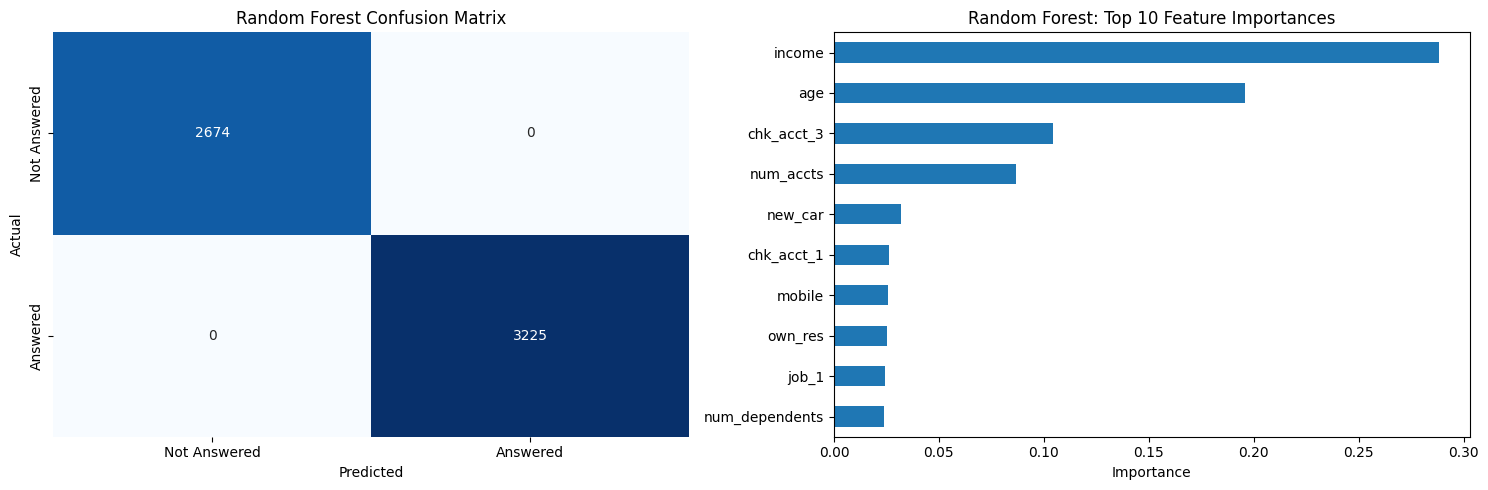

In [53]:
# 5.4 Random forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_profit, rf_tp, rf_fp = calculate_profit(y_test, y_pred_rf)
print(f"Random forest test accuracy: {rf_accuracy:.4f}   profit: ${rf_profit:,}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Not Answered', 'Answered'], yticklabels=['Not Answered', 'Answered'], ax=axes[0])
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

rf_imp = pd.Series(rf_model.feature_importances_, index=X.columns).nlargest(10).sort_values()
rf_imp.plot(kind='barh', ax=axes[1])
axes[1].set_title('Random Forest: Top 10 Feature Importances')
axes[1].set_xlabel('Importance')
plt.tight_layout()
plt.show()

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest had higher test accuracy than the tuned decision tree: 100% vs. 83.8%. But the 100% needs a caveat. The dataset only has 469 unique customer profiles, each repeated about 64 times, so nearly every customer in the test set has an identical copy in the training set. The forest (which also scores 100% on training data) is mostly recognizing customers it has already seen. On truly new customers, accuracy would likely be lower.
2. The most important variables in the random forest were income, age, checking account in the highest category (chk_acct_3) and number of accounts. These are mostly the same variables that appear near the top of my decision tree. The tree splits first on chk_acct_3 and then on income. The forest ranks income first and age higher than the tree did.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

Gradient boosting test accuracy: 0.8944   profit: $206,750


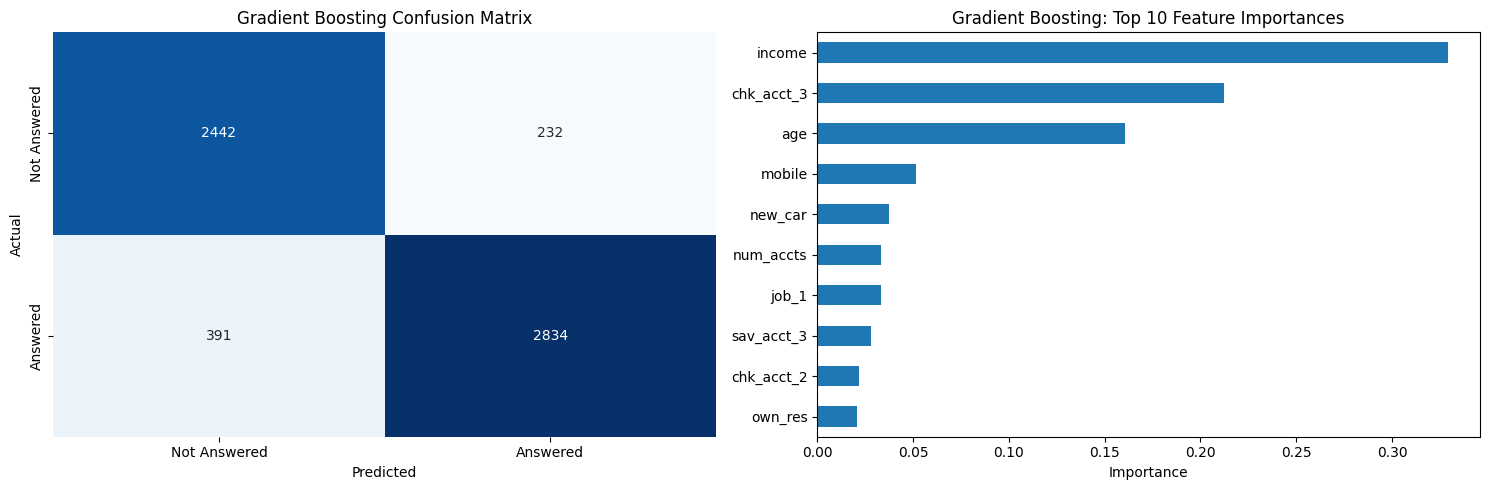

In [55]:
# 5.5 Gradient boosting
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_profit, gb_tp, gb_fp = calculate_profit(y_test, y_pred_gb)
print(f"Gradient boosting test accuracy: {gb_accuracy:.4f}   profit: ${gb_profit:,}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_gb), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Not Answered', 'Answered'], yticklabels=['Not Answered', 'Answered'], ax=axes[0])
axes[0].set_title('Gradient Boosting Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

gb_imp = pd.Series(gb_model.feature_importances_, index=X.columns).nlargest(10).sort_values()
gb_imp.plot(kind='barh', ax=axes[1])
axes[1].set_title('Gradient Boosting: Top 10 Feature Importances')
axes[1].set_xlabel('Importance')
plt.tight_layout()
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. The random forest had better test accuracy (100% vs. 89.4%). Gradient boosting also used income, chk_acct_3 and age as its top three features.
2. A random forest builds many deep trees independently, each on a random sample of the data and features, and then takes a vote. Gradient boosting builds small trees one after another, and each new tree focuses on fixing the mistakes the earlier trees made. The forest reduces error by averaging many trees together, while boosting reduces error by gradually correcting itself.

## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

              Model  Test Accuracy  True Positives  False Positives  Estimated Profit
Tuned Decision Tree         0.8379            2584              315            185925
      Random Forest         1.0000            3225                0            241875
  Gradient Boosting         0.8944            2834              232            206750

Call-everyone profit for comparison: $175,025


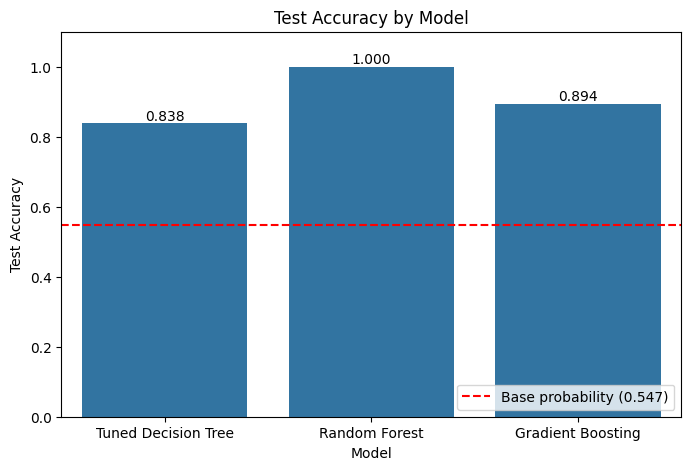

In [56]:
# 5.6 Compare models on accuracy and profit
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tuned_dt_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tuned_dt_tp, rf_tp, gb_tp],
    'False Positives': [tuned_dt_fp, rf_fp, gb_fp],
    'Estimated Profit': [tuned_dt_profit, rf_profit, gb_profit]
})
print(model_results.round(4).to_string(index=False))
print(f"\nCall-everyone profit for comparison: ${default_profit:,}")

plt.figure(figsize=(8, 5))
ax = sns.barplot(x='Model', y='Test Accuracy', data=model_results)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.axhline(base_prob, color='red', linestyle='--', label=f'Base probability ({base_prob:.3f})')
plt.title('Test Accuracy by Model')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [58]:
# 5.7 Apply the recommended model to new customers
new_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_url)

# Same cleanup as 2.1-2.3 (no rows removed: we need a prediction for every new customer)
df_new_clean = df_new.drop(columns=['customer_id'])
for col in ['female', 'new_car']:
    df_new_clean[col] = df_new_clean[col].astype(int)
for col in ['job', 'chk_acct', 'sav_acct']:
    df_new_clean[col] = df_new_clean[col].astype('category')

# Match the training columns exactly (same dummy columns, same order)
X_new = pd.get_dummies(df_new_clean, drop_first=True)
X_new = X_new.reindex(columns=X.columns, fill_value=0)

best_model = rf_model
new_predictions = best_model.predict(X_new)
df_new['predicted_answer'] = new_predictions

print("Predicted outcomes for new customers:")
print(df_new['predicted_answer'].value_counts().rename({True: 'Will answer', False: 'Will not answer'}))

Predicted outcomes for new customers:
predicted_answer
Will answer        545
Will not answer    455
Name: count, dtype: int64


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. The random forest produced the highest estimated profit (\$241,875) and was also the most accurate model (100%). Gradient boosting was second (\$206,750, 89.4%) and the tuned decision tree was third (\$185,925, 83.8%). All three beat calling everyone (\$175,025).
2. A business might choose a model with slightly lower accuracy if it's easier to explain, cheaper to run or more reliable on new data. Accuracy also treats all errors equally, but here missing a customer who would answer costs \$75 while a wasted call costs only \$25. So the model that makes the most money isn't always the one with the best accuracy.
3. The decision tree is the easiest to explain to the Director of Sales because you can literally show the rules, like "customers with the highest checking balance and income under about \$39K answer about 87% of the time." The random forest and gradient boosting models combine 100 trees each, so you can show which variables matter most but not the exact reasoning behind each prediction. I recommend the random forest because it had the highest profit (\$241,875) and accuracy (100%) on the test set. One caveat: that 100% is inflated, because the data only has 469 unique customer profiles repeated about 64 times, so the forest is mostly recognizing customers it has already seen. Gradient boosting would be a strong backup. It earned \$206,750, and its training and test accuracy are nearly identical (89.4% for both), which suggests it would hold up well on truly new customers.

# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 6.1 Yes, once the model was improved. The original depth-4 decision tree made less money than calling everyone (\$133,200 vs. \$175,025) because it skipped too many customers who would have answered. After tuning, every model beat the call-everyone baseline on the test set: the tuned decision tree by \$10,900, gradient boosting by \$31,725 and the random forest by \$66,850.

6.2 AdviseInvest can score each customer as soon as they finish the profile form and schedule a call. Customers predicted to answer get priority for the 8 call slots each hour. Customers predicted not to answer can get a reminder text or email first, or they can be scheduled into extra slots. The predicted number of answers per hour can also be used to set how many reps to staff, so reps aren't left sitting idle.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [30]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 10 image(s).
[NbConvertApp] Writing 808693 bytes to assignment_10_classification.html
